# **Oasis Infobyte - Data Science Internship**

# **Maragathavalli C S**
# **Task 3: Car Price Prediction with Machine Learning**

**Objective: Predict the selling price of a used car using regression models.**

**Import libraries and load the dataset**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style = 'whitegrid')
pd.set_option('display.max_columns', None)



In [5]:
from google.colab import files
uploaded = files.upload()

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO.csv


In [8]:
df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
print("Dataset shape:", df.shape)
display(df.head())
print('\nColumn names:', df.columns.tolist())

Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Column names: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


**Data Cleaning**

In [12]:
# Standardize column names and text values.
df.columns = df.columns.str.strip()

# Remove duplicate rows.
before = len(df)
df = df.drop_duplicates().copy()
print(f"Duplicate rows removed: {before - len(df)}")

# Normalize common categorical columns if they exist.
for col in ['Fuel_Type', 'Seller_Type', 'Transmission']:
  if col in df.columns:
    df[col] = df[col].astype('string').str.strip().str.lower()

# Convert expected numeric columns safely.
for col in ['Year', 'Selling_Price', 'Present_Price', 'Kms_Driven']:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Missing values before imputation:')
display(df.isnull().sum().to_frame('missing values'))

# Selling_Price is the target; rows without it cannot train a supervised model.
df = df.dropna(subset = ['selling_price']).copy()
print('Shape after cleaning:', df.shape)
display(df.describe(include = 'all').T)

Duplicate rows removed: 0
Missing values before imputation:


,missing values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


Shape after cleaning: (3577, 8)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,3577,1491,Maruti Swift Dzire VDI,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3577.0,NaN,NaN,NaN,2012.962538,4.251759,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3577.0,NaN,NaN,NaN,473912.542074,509301.809816,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3577.0,NaN,NaN,NaN,69250.545709,47579.940016,1.0,36000.0,60000.0,90000.0,806599.0
fuel,3577,5,Diesel,1800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,3577,3,Individual,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,3577,2,Manual,3265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,3577,5,First Owner,2218,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Feature engineering: car age and brand**

In [13]:
# Calculate age from the Year column.
current_year = pd.Timestamp.now().year
if 'Year' in df.columns:
    df['Car_Age'] = (current_year - df['Year']).clip(lower=0)

# Extract the first word of the car name as a simple brand feature.
name_col = next((c for c in ['Car_Name', 'CarName', 'car_name'] if c in df.columns), None)
if name_col:
    df['Brand'] = (df[name_col].astype('string').str.strip()
                   .str.split().str[0].str.lower())

display(df.head())
print('Features created:', [c for c in ['Car_Age', 'Brand'] if c in df.columns])

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


Features created: []


**Exploratory Data Analysis (EDA)**

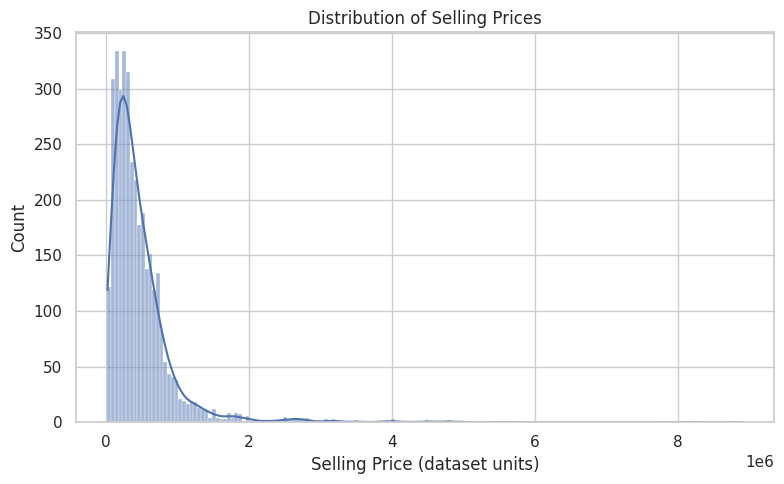

In [15]:
# Distribution of selling prices.
plt.figure(figsize=(8, 5))
sns.histplot(df['selling_price'], kde=True)
plt.title('Distribution of Selling Prices')
plt.xlabel('Selling Price (dataset units)')
plt.tight_layout()
plt.show()

# Selling price by fuel type.
if 'Fuel_Type' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')
    plt.title('Selling Price vs Fuel Type')
    plt.tight_layout()
    plt.show()

# Selling price vs car age.
if 'Car_Age' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='Car_Age', y='Selling_Price', alpha=0.7)
    plt.title('Selling Price vs Car Age')
    plt.tight_layout()
    plt.show()

# Optional additional plot: mileage vs selling price.
if 'Kms_Driven' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='Kms_Driven', y='Selling_Price', alpha=0.7)
    plt.title('Selling Price vs Kilometers Driven')
    plt.tight_layout()
    plt.show()

**Correlation heatmap**

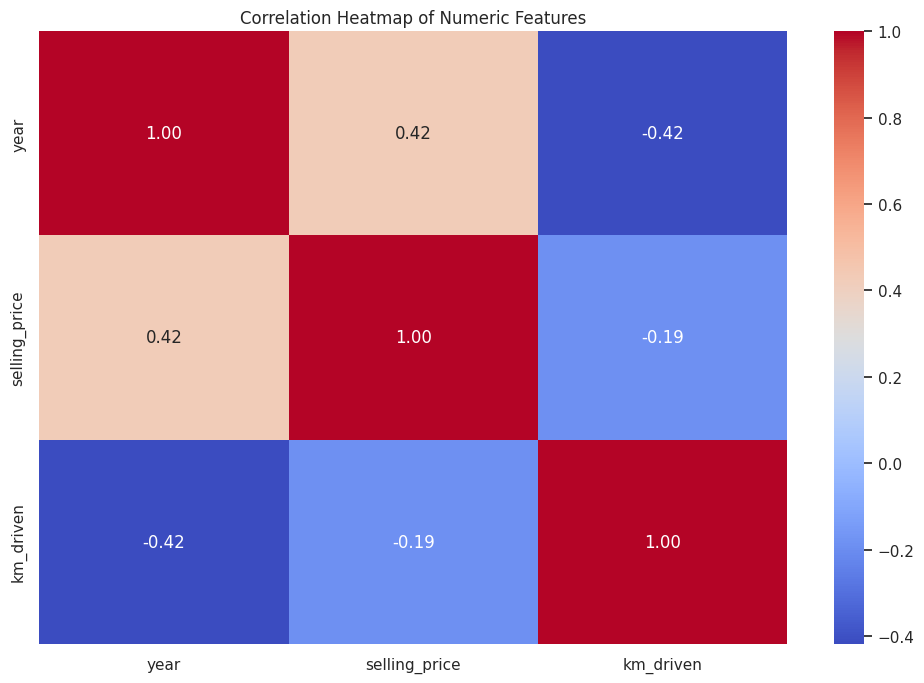

In [16]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', square=False)
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

**Prepare features and encode categorical variables**

In [18]:
target = 'selling_price'

# Remove the target and raw car-name text from the predictors.
drop_cols = [target]
if name_col:
    drop_cols.append(name_col)
X = df.drop(columns=drop_cols, errors='ignore').copy()
y = df[target].copy()

# Drop columns that are entirely empty and split by data type.
X = X.dropna(axis=1, how='all')
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Numeric features: ['year', 'km_driven']
Categorical features: ['name', 'fuel', 'seller_type', 'transmission', 'owner']
Training rows: 2861
Testing rows: 716


**Train two regression models**

In [19]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=300, random_state=42, min_samples_leaf=1, n_jobs=-1
    )
}

trained_models = {}
results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[model_name] = pipeline
    results.append({'Model': model_name, 'MAE': mae, 'RMSE': rmse, 'R² Score': r2})

results_df = pd.DataFrame(results).sort_values('RMSE').reset_index(drop=True)
display(results_df.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R² Score': '{:.3f}'}))
best_model_name = results_df.loc[0, 'Model']
best_model = trained_models[best_model_name]
print('Best model based on lowest RMSE:', best_model_name)

,Model,MAE,RMSE,R² Score
0,Random Forest Regressor,149902.591,394761.732,0.516
1,Linear Regression,212414.776,441078.347,0.396


Best model based on lowest RMSE: Random Forest Regressor


**Compare actual and predicted prices**

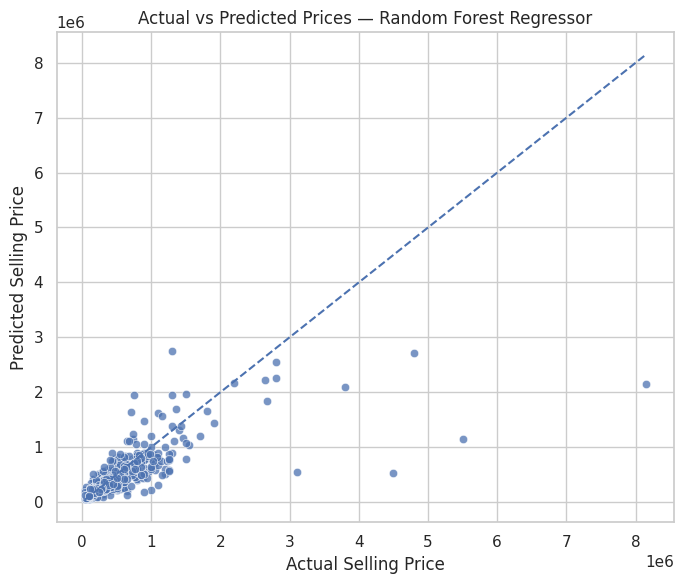

In [20]:
best_predictions = best_model.predict(X_test)
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.75)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle='--')
plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.title(f'Actual vs Predicted Prices — {best_model_name}')
plt.tight_layout()
plt.show()

**Feature importance for the best model**

,Feature,Importance
0,num__year,0.187081
1316,cat__transmission_Manual,0.127000
1315,cat__transmission_Automatic,0.118593
23,cat__name_Audi RS7 2015-2019 Sportback Perform...,0.083125
1309,cat__fuel_Diesel,0.079945
1,num__km_driven,0.058925
1311,cat__fuel_Petrol,0.044296
544,cat__name_Land Rover Discovery S 2.0 SD4,0.016769
547,cat__name_Land Rover Range Rover 4.4 Diesel LW...,0.011477
1305,cat__name_Volvo XC 90 D5 Inscription BSIV,0.010295


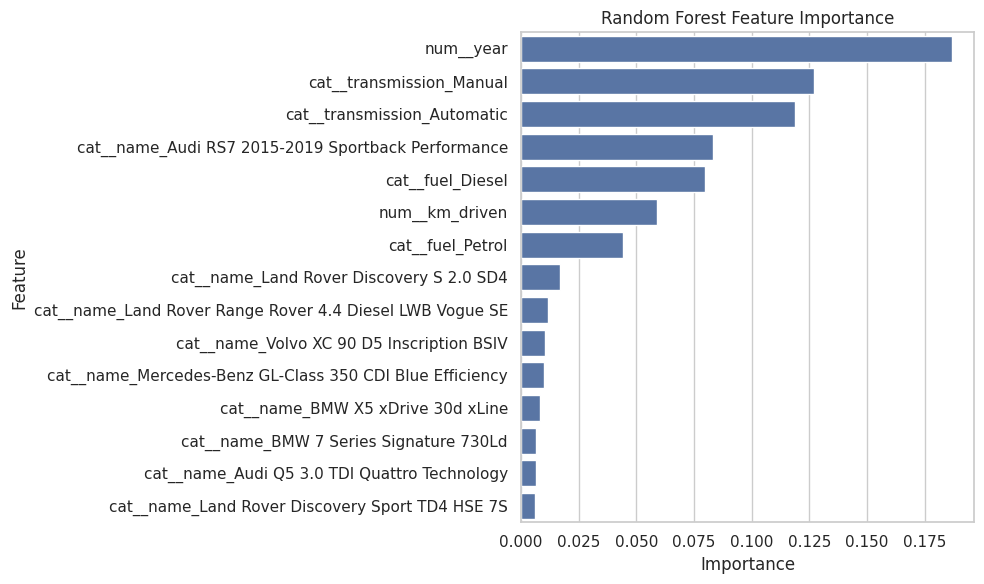

In [21]:
model_step = best_model.named_steps['model']
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

if hasattr(model_step, 'feature_importances_'):
    importance_values = model_step.feature_importances_
    importance_title = 'Random Forest Feature Importance'
elif hasattr(model_step, 'coef_'):
    importance_values = np.abs(np.ravel(model_step.coef_))
    importance_title = 'Absolute Linear Regression Coefficients (importance proxy)'
else:
    importance_values = None

if importance_values is not None:
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importance_values
    }).sort_values('Importance', ascending=False).head(15)
    display(importance_df)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x='Importance', y='Feature')
    plt.title(importance_title)
    plt.tight_layout()
    plt.show()
else:
    print('Feature importance is not available for this model.')

**Try a sample prediction**

In [22]:
# Example: use an existing test row to demonstrate prediction.
sample = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample)[0]
display(sample)
print(f'Actual selling price: {actual_price:.2f}')
print(f'Predicted selling price: {predicted_price:.2f}')

,name,year,km_driven,fuel,seller_type,transmission,owner
1045,Maruti Eeco 7 Seater Standard BSIV,2018,20000,Petrol,Individual,Manual,First Owner


Actual selling price: 270000.00
Predicted selling price: 394724.44


### **Model Training and Evaluation**

Two regression algorithms, Linear Regression and Random Forest Regressor, were trained to predict used-car selling prices. The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

The Random Forest Regressor performed better, achieving an MAE of 149,902.591, an RMSE of 394,761.732, and an R² score of 0.516. Linear Regression achieved an MAE of 212,414.776, an RMSE of 441,078.347, and an R² score of 0.396.

Therefore, the Random Forest Regressor was selected as the best-performing model among the two models tested. Further improvements may be possible through hyperparameter tuning, additional feature engineering, and outlier analysis.